# From four car measurements to two meaningful coordinates
## A visual, hands-on introduction to PCA
**Applied AI master's class · approximately 110 minutes**

Can we compress a car's technical profile into two numbers and still see useful patterns?

You will explore real measurements, calculate z-scores and covariance, find principal directions, interpret the resulting map, reconstruct the original measurements, and verify your calculations with scikit-learn. Basic Python is sufficient. Read each explanation, predict the result, then run the next cell.

Suggested pacing: exploration 15 min, scaling 15 min, projections 20 min, manual PCA 25 min, interpretation and reconstruction 20 min, discussion 15 min. The prediction extension is optional.

Open in Google Colab or Jupyter and run cells in order. The dataset is embedded, so data loading requires no download. Package installation, if needed, requires internet.

In [1]:
# Run only if packages are missing.
# %pip install numpy pandas matplotlib scikit-learn

In [2]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
np.set_printoptions(precision=4, suppress=True)


## 1. Meet the cars
Auto MPG contains 398 historical car records. We use the CSV distributed with seaborn, derived from the UCI Auto MPG dataset. These observations describe older cars, so conclusions apply to this sample.

| Column | Meaning | Unit | Role |
|---|---|---|---|
| displacement | Engine displacement, a measure of engine size | cubic inches | PCA input |
| horsepower | Engine power | horsepower | PCA input |
| weight | Vehicle weight | pounds | PCA input |
| acceleration | Time to accelerate from 0 to 60 mph | seconds | PCA input |
| mpg | Fuel economy, distance per gallon | miles per US gallon | Reveal after PCA |
| name | Car identification | text | Label selected points |

**A larger acceleration value means a longer time to reach 60 mph.** Higher MPG means better fuel economy. We exclude cylinders, year and origin to keep the first analysis focused on four continuous physical measurements.

Sources: [UCI Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) · [CSV used here](https://github.com/mwaskom/seaborn-data/blob/master/mpg.csv)

**Predict** Which measurements might provide overlapping information?

In [3]:
CSV_DATA = "mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name\n18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu\n15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320\n18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite\n16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst\n17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino\n15.0,8,429.0,198.0,4341,10.0,70,usa,ford galaxie 500\n14.0,8,454.0,220.0,4354,9.0,70,usa,chevrolet impala\n14.0,8,440.0,215.0,4312,8.5,70,usa,plymouth fury iii\n14.0,8,455.0,225.0,4425,10.0,70,usa,pontiac catalina\n15.0,8,390.0,190.0,3850,8.5,70,usa,amc ambassador dpl\n15.0,8,383.0,170.0,3563,10.0,70,usa,dodge challenger se\n14.0,8,340.0,160.0,3609,8.0,70,usa,plymouth 'cuda 340\n15.0,8,400.0,150.0,3761,9.5,70,usa,chevrolet monte carlo\n14.0,8,455.0,225.0,3086,10.0,70,usa,buick estate wagon (sw)\n24.0,4,113.0,95.0,2372,15.0,70,japan,toyota corona mark ii\n22.0,6,198.0,95.0,2833,15.5,70,usa,plymouth duster\n18.0,6,199.0,97.0,2774,15.5,70,usa,amc hornet\n21.0,6,200.0,85.0,2587,16.0,70,usa,ford maverick\n27.0,4,97.0,88.0,2130,14.5,70,japan,datsun pl510\n26.0,4,97.0,46.0,1835,20.5,70,europe,volkswagen 1131 deluxe sedan\n25.0,4,110.0,87.0,2672,17.5,70,europe,peugeot 504\n24.0,4,107.0,90.0,2430,14.5,70,europe,audi 100 ls\n25.0,4,104.0,95.0,2375,17.5,70,europe,saab 99e\n26.0,4,121.0,113.0,2234,12.5,70,europe,bmw 2002\n21.0,6,199.0,90.0,2648,15.0,70,usa,amc gremlin\n10.0,8,360.0,215.0,4615,14.0,70,usa,ford f250\n10.0,8,307.0,200.0,4376,15.0,70,usa,chevy c20\n11.0,8,318.0,210.0,4382,13.5,70,usa,dodge d200\n9.0,8,304.0,193.0,4732,18.5,70,usa,hi 1200d\n27.0,4,97.0,88.0,2130,14.5,71,japan,datsun pl510\n28.0,4,140.0,90.0,2264,15.5,71,usa,chevrolet vega 2300\n25.0,4,113.0,95.0,2228,14.0,71,japan,toyota corona\n25.0,4,98.0,,2046,19.0,71,usa,ford pinto\n19.0,6,232.0,100.0,2634,13.0,71,usa,amc gremlin\n16.0,6,225.0,105.0,3439,15.5,71,usa,plymouth satellite custom\n17.0,6,250.0,100.0,3329,15.5,71,usa,chevrolet chevelle malibu\n19.0,6,250.0,88.0,3302,15.5,71,usa,ford torino 500\n18.0,6,232.0,100.0,3288,15.5,71,usa,amc matador\n14.0,8,350.0,165.0,4209,12.0,71,usa,chevrolet impala\n14.0,8,400.0,175.0,4464,11.5,71,usa,pontiac catalina brougham\n14.0,8,351.0,153.0,4154,13.5,71,usa,ford galaxie 500\n14.0,8,318.0,150.0,4096,13.0,71,usa,plymouth fury iii\n12.0,8,383.0,180.0,4955,11.5,71,usa,dodge monaco (sw)\n13.0,8,400.0,170.0,4746,12.0,71,usa,ford country squire (sw)\n13.0,8,400.0,175.0,5140,12.0,71,usa,pontiac safari (sw)\n18.0,6,258.0,110.0,2962,13.5,71,usa,amc hornet sportabout (sw)\n22.0,4,140.0,72.0,2408,19.0,71,usa,chevrolet vega (sw)\n19.0,6,250.0,100.0,3282,15.0,71,usa,pontiac firebird\n18.0,6,250.0,88.0,3139,14.5,71,usa,ford mustang\n23.0,4,122.0,86.0,2220,14.0,71,usa,mercury capri 2000\n28.0,4,116.0,90.0,2123,14.0,71,europe,opel 1900\n30.0,4,79.0,70.0,2074,19.5,71,europe,peugeot 304\n30.0,4,88.0,76.0,2065,14.5,71,europe,fiat 124b\n31.0,4,71.0,65.0,1773,19.0,71,japan,toyota corolla 1200\n35.0,4,72.0,69.0,1613,18.0,71,japan,datsun 1200\n27.0,4,97.0,60.0,1834,19.0,71,europe,volkswagen model 111\n26.0,4,91.0,70.0,1955,20.5,71,usa,plymouth cricket\n24.0,4,113.0,95.0,2278,15.5,72,japan,toyota corona hardtop\n25.0,4,97.5,80.0,2126,17.0,72,usa,dodge colt hardtop\n23.0,4,97.0,54.0,2254,23.5,72,europe,volkswagen type 3\n20.0,4,140.0,90.0,2408,19.5,72,usa,chevrolet vega\n21.0,4,122.0,86.0,2226,16.5,72,usa,ford pinto runabout\n13.0,8,350.0,165.0,4274,12.0,72,usa,chevrolet impala\n14.0,8,400.0,175.0,4385,12.0,72,usa,pontiac catalina\n15.0,8,318.0,150.0,4135,13.5,72,usa,plymouth fury iii\n14.0,8,351.0,153.0,4129,13.0,72,usa,ford galaxie 500\n17.0,8,304.0,150.0,3672,11.5,72,usa,amc ambassador sst\n11.0,8,429.0,208.0,4633,11.0,72,usa,mercury marquis\n13.0,8,350.0,155.0,4502,13.5,72,usa,buick lesabre custom\n12.0,8,350.0,160.0,4456,13.5,72,usa,oldsmobile delta 88 royale\n13.0,8,400.0,190.0,4422,12.5,72,usa,chrysler newport royal\n19.0,3,70.0,97.0,2330,13.5,72,japan,mazda rx2 coupe\n15.0,8,304.0,150.0,3892,12.5,72,usa,amc matador (sw)\n13.0,8,307.0,130.0,4098,14.0,72,usa,chevrolet chevelle concours (sw)\n13.0,8,302.0,140.0,4294,16.0,72,usa,ford gran torino (sw)\n14.0,8,318.0,150.0,4077,14.0,72,usa,plymouth satellite custom (sw)\n18.0,4,121.0,112.0,2933,14.5,72,europe,volvo 145e (sw)\n22.0,4,121.0,76.0,2511,18.0,72,europe,volkswagen 411 (sw)\n21.0,4,120.0,87.0,2979,19.5,72,europe,peugeot 504 (sw)\n26.0,4,96.0,69.0,2189,18.0,72,europe,renault 12 (sw)\n22.0,4,122.0,86.0,2395,16.0,72,usa,ford pinto (sw)\n28.0,4,97.0,92.0,2288,17.0,72,japan,datsun 510 (sw)\n23.0,4,120.0,97.0,2506,14.5,72,japan,toyouta corona mark ii (sw)\n28.0,4,98.0,80.0,2164,15.0,72,usa,dodge colt (sw)\n27.0,4,97.0,88.0,2100,16.5,72,japan,toyota corolla 1600 (sw)\n13.0,8,350.0,175.0,4100,13.0,73,usa,buick century 350\n14.0,8,304.0,150.0,3672,11.5,73,usa,amc matador\n13.0,8,350.0,145.0,3988,13.0,73,usa,chevrolet malibu\n14.0,8,302.0,137.0,4042,14.5,73,usa,ford gran torino\n15.0,8,318.0,150.0,3777,12.5,73,usa,dodge coronet custom\n12.0,8,429.0,198.0,4952,11.5,73,usa,mercury marquis brougham\n13.0,8,400.0,150.0,4464,12.0,73,usa,chevrolet caprice classic\n13.0,8,351.0,158.0,4363,13.0,73,usa,ford ltd\n14.0,8,318.0,150.0,4237,14.5,73,usa,plymouth fury gran sedan\n13.0,8,440.0,215.0,4735,11.0,73,usa,chrysler new yorker brougham\n12.0,8,455.0,225.0,4951,11.0,73,usa,buick electra 225 custom\n13.0,8,360.0,175.0,3821,11.0,73,usa,amc ambassador brougham\n18.0,6,225.0,105.0,3121,16.5,73,usa,plymouth valiant\n16.0,6,250.0,100.0,3278,18.0,73,usa,chevrolet nova custom\n18.0,6,232.0,100.0,2945,16.0,73,usa,amc hornet\n18.0,6,250.0,88.0,3021,16.5,73,usa,ford maverick\n23.0,6,198.0,95.0,2904,16.0,73,usa,plymouth duster\n26.0,4,97.0,46.0,1950,21.0,73,europe,volkswagen super beetle\n11.0,8,400.0,150.0,4997,14.0,73,usa,chevrolet impala\n12.0,8,400.0,167.0,4906,12.5,73,usa,ford country\n13.0,8,360.0,170.0,4654,13.0,73,usa,plymouth custom suburb\n12.0,8,350.0,180.0,4499,12.5,73,usa,oldsmobile vista cruiser\n18.0,6,232.0,100.0,2789,15.0,73,usa,amc gremlin\n20.0,4,97.0,88.0,2279,19.0,73,japan,toyota carina\n21.0,4,140.0,72.0,2401,19.5,73,usa,chevrolet vega\n22.0,4,108.0,94.0,2379,16.5,73,japan,datsun 610\n18.0,3,70.0,90.0,2124,13.5,73,japan,maxda rx3\n19.0,4,122.0,85.0,2310,18.5,73,usa,ford pinto\n21.0,6,155.0,107.0,2472,14.0,73,usa,mercury capri v6\n26.0,4,98.0,90.0,2265,15.5,73,europe,fiat 124 sport coupe\n15.0,8,350.0,145.0,4082,13.0,73,usa,chevrolet monte carlo s\n16.0,8,400.0,230.0,4278,9.5,73,usa,pontiac grand prix\n29.0,4,68.0,49.0,1867,19.5,73,europe,fiat 128\n24.0,4,116.0,75.0,2158,15.5,73,europe,opel manta\n20.0,4,114.0,91.0,2582,14.0,73,europe,audi 100ls\n19.0,4,121.0,112.0,2868,15.5,73,europe,volvo 144ea\n15.0,8,318.0,150.0,3399,11.0,73,usa,dodge dart custom\n24.0,4,121.0,110.0,2660,14.0,73,europe,saab 99le\n20.0,6,156.0,122.0,2807,13.5,73,japan,toyota mark ii\n11.0,8,350.0,180.0,3664,11.0,73,usa,oldsmobile omega\n20.0,6,198.0,95.0,3102,16.5,74,usa,plymouth duster\n21.0,6,200.0,,2875,17.0,74,usa,ford maverick\n19.0,6,232.0,100.0,2901,16.0,74,usa,amc hornet\n15.0,6,250.0,100.0,3336,17.0,74,usa,chevrolet nova\n31.0,4,79.0,67.0,1950,19.0,74,japan,datsun b210\n26.0,4,122.0,80.0,2451,16.5,74,usa,ford pinto\n32.0,4,71.0,65.0,1836,21.0,74,japan,toyota corolla 1200\n25.0,4,140.0,75.0,2542,17.0,74,usa,chevrolet vega\n16.0,6,250.0,100.0,3781,17.0,74,usa,chevrolet chevelle malibu classic\n16.0,6,258.0,110.0,3632,18.0,74,usa,amc matador\n18.0,6,225.0,105.0,3613,16.5,74,usa,plymouth satellite sebring\n16.0,8,302.0,140.0,4141,14.0,74,usa,ford gran torino\n13.0,8,350.0,150.0,4699,14.5,74,usa,buick century luxus (sw)\n14.0,8,318.0,150.0,4457,13.5,74,usa,dodge coronet custom (sw)\n14.0,8,302.0,140.0,4638,16.0,74,usa,ford gran torino (sw)\n14.0,8,304.0,150.0,4257,15.5,74,usa,amc matador (sw)\n29.0,4,98.0,83.0,2219,16.5,74,europe,audi fox\n26.0,4,79.0,67.0,1963,15.5,74,europe,volkswagen dasher\n26.0,4,97.0,78.0,2300,14.5,74,europe,opel manta\n31.0,4,76.0,52.0,1649,16.5,74,japan,toyota corona\n32.0,4,83.0,61.0,2003,19.0,74,japan,datsun 710\n28.0,4,90.0,75.0,2125,14.5,74,usa,dodge colt\n24.0,4,90.0,75.0,2108,15.5,74,europe,fiat 128\n26.0,4,116.0,75.0,2246,14.0,74,europe,fiat 124 tc\n24.0,4,120.0,97.0,2489,15.0,74,japan,honda civic\n26.0,4,108.0,93.0,2391,15.5,74,japan,subaru\n31.0,4,79.0,67.0,2000,16.0,74,europe,fiat x1.9\n19.0,6,225.0,95.0,3264,16.0,75,usa,plymouth valiant custom\n18.0,6,250.0,105.0,3459,16.0,75,usa,chevrolet nova\n15.0,6,250.0,72.0,3432,21.0,75,usa,mercury monarch\n15.0,6,250.0,72.0,3158,19.5,75,usa,ford maverick\n16.0,8,400.0,170.0,4668,11.5,75,usa,pontiac catalina\n15.0,8,350.0,145.0,4440,14.0,75,usa,chevrolet bel air\n16.0,8,318.0,150.0,4498,14.5,75,usa,plymouth grand fury\n14.0,8,351.0,148.0,4657,13.5,75,usa,ford ltd\n17.0,6,231.0,110.0,3907,21.0,75,usa,buick century\n16.0,6,250.0,105.0,3897,18.5,75,usa,chevroelt chevelle malibu\n15.0,6,258.0,110.0,3730,19.0,75,usa,amc matador\n18.0,6,225.0,95.0,3785,19.0,75,usa,plymouth fury\n21.0,6,231.0,110.0,3039,15.0,75,usa,buick skyhawk\n20.0,8,262.0,110.0,3221,13.5,75,usa,chevrolet monza 2+2\n13.0,8,302.0,129.0,3169,12.0,75,usa,ford mustang ii\n29.0,4,97.0,75.0,2171,16.0,75,japan,toyota corolla\n23.0,4,140.0,83.0,2639,17.0,75,usa,ford pinto\n20.0,6,232.0,100.0,2914,16.0,75,usa,amc gremlin\n23.0,4,140.0,78.0,2592,18.5,75,usa,pontiac astro\n24.0,4,134.0,96.0,2702,13.5,75,japan,toyota corona\n25.0,4,90.0,71.0,2223,16.5,75,europe,volkswagen dasher\n24.0,4,119.0,97.0,2545,17.0,75,japan,datsun 710\n18.0,6,171.0,97.0,2984,14.5,75,usa,ford pinto\n29.0,4,90.0,70.0,1937,14.0,75,europe,volkswagen rabbit\n19.0,6,232.0,90.0,3211,17.0,75,usa,amc pacer\n23.0,4,115.0,95.0,2694,15.0,75,europe,audi 100ls\n23.0,4,120.0,88.0,2957,17.0,75,europe,peugeot 504\n22.0,4,121.0,98.0,2945,14.5,75,europe,volvo 244dl\n25.0,4,121.0,115.0,2671,13.5,75,europe,saab 99le\n33.0,4,91.0,53.0,1795,17.5,75,japan,honda civic cvcc\n28.0,4,107.0,86.0,2464,15.5,76,europe,fiat 131\n25.0,4,116.0,81.0,2220,16.9,76,europe,opel 1900\n25.0,4,140.0,92.0,2572,14.9,76,usa,capri ii\n26.0,4,98.0,79.0,2255,17.7,76,usa,dodge colt\n27.0,4,101.0,83.0,2202,15.3,76,europe,renault 12tl\n17.5,8,305.0,140.0,4215,13.0,76,usa,chevrolet chevelle malibu classic\n16.0,8,318.0,150.0,4190,13.0,76,usa,dodge coronet brougham\n15.5,8,304.0,120.0,3962,13.9,76,usa,amc matador\n14.5,8,351.0,152.0,4215,12.8,76,usa,ford gran torino\n22.0,6,225.0,100.0,3233,15.4,76,usa,plymouth valiant\n22.0,6,250.0,105.0,3353,14.5,76,usa,chevrolet nova\n24.0,6,200.0,81.0,3012,17.6,76,usa,ford maverick\n22.5,6,232.0,90.0,3085,17.6,76,usa,amc hornet\n29.0,4,85.0,52.0,2035,22.2,76,usa,chevrolet chevette\n24.5,4,98.0,60.0,2164,22.1,76,usa,chevrolet woody\n29.0,4,90.0,70.0,1937,14.2,76,europe,vw rabbit\n33.0,4,91.0,53.0,1795,17.4,76,japan,honda civic\n20.0,6,225.0,100.0,3651,17.7,76,usa,dodge aspen se\n18.0,6,250.0,78.0,3574,21.0,76,usa,ford granada ghia\n18.5,6,250.0,110.0,3645,16.2,76,usa,pontiac ventura sj\n17.5,6,258.0,95.0,3193,17.8,76,usa,amc pacer d/l\n29.5,4,97.0,71.0,1825,12.2,76,europe,volkswagen rabbit\n32.0,4,85.0,70.0,1990,17.0,76,japan,datsun b-210\n28.0,4,97.0,75.0,2155,16.4,76,japan,toyota corolla\n26.5,4,140.0,72.0,2565,13.6,76,usa,ford pinto\n20.0,4,130.0,102.0,3150,15.7,76,europe,volvo 245\n13.0,8,318.0,150.0,3940,13.2,76,usa,plymouth volare premier v8\n19.0,4,120.0,88.0,3270,21.9,76,europe,peugeot 504\n19.0,6,156.0,108.0,2930,15.5,76,japan,toyota mark ii\n16.5,6,168.0,120.0,3820,16.7,76,europe,mercedes-benz 280s\n16.5,8,350.0,180.0,4380,12.1,76,usa,cadillac seville\n13.0,8,350.0,145.0,4055,12.0,76,usa,chevy c10\n13.0,8,302.0,130.0,3870,15.0,76,usa,ford f108\n13.0,8,318.0,150.0,3755,14.0,76,usa,dodge d100\n31.5,4,98.0,68.0,2045,18.5,77,japan,honda accord cvcc\n30.0,4,111.0,80.0,2155,14.8,77,usa,buick opel isuzu deluxe\n36.0,4,79.0,58.0,1825,18.6,77,europe,renault 5 gtl\n25.5,4,122.0,96.0,2300,15.5,77,usa,plymouth arrow gs\n33.5,4,85.0,70.0,1945,16.8,77,japan,datsun f-10 hatchback\n17.5,8,305.0,145.0,3880,12.5,77,usa,chevrolet caprice classic\n17.0,8,260.0,110.0,4060,19.0,77,usa,oldsmobile cutlass supreme\n15.5,8,318.0,145.0,4140,13.7,77,usa,dodge monaco brougham\n15.0,8,302.0,130.0,4295,14.9,77,usa,mercury cougar brougham\n17.5,6,250.0,110.0,3520,16.4,77,usa,chevrolet concours\n20.5,6,231.0,105.0,3425,16.9,77,usa,buick skylark\n19.0,6,225.0,100.0,3630,17.7,77,usa,plymouth volare custom\n18.5,6,250.0,98.0,3525,19.0,77,usa,ford granada\n16.0,8,400.0,180.0,4220,11.1,77,usa,pontiac grand prix lj\n15.5,8,350.0,170.0,4165,11.4,77,usa,chevrolet monte carlo landau\n15.5,8,400.0,190.0,4325,12.2,77,usa,chrysler cordoba\n16.0,8,351.0,149.0,4335,14.5,77,usa,ford thunderbird\n29.0,4,97.0,78.0,1940,14.5,77,europe,volkswagen rabbit custom\n24.5,4,151.0,88.0,2740,16.0,77,usa,pontiac sunbird coupe\n26.0,4,97.0,75.0,2265,18.2,77,japan,toyota corolla liftback\n25.5,4,140.0,89.0,2755,15.8,77,usa,ford mustang ii 2+2\n30.5,4,98.0,63.0,2051,17.0,77,usa,chevrolet chevette\n33.5,4,98.0,83.0,2075,15.9,77,usa,dodge colt m/m\n30.0,4,97.0,67.0,1985,16.4,77,japan,subaru dl\n30.5,4,97.0,78.0,2190,14.1,77,europe,volkswagen dasher\n22.0,6,146.0,97.0,2815,14.5,77,japan,datsun 810\n21.5,4,121.0,110.0,2600,12.8,77,europe,bmw 320i\n21.5,3,80.0,110.0,2720,13.5,77,japan,mazda rx-4\n43.1,4,90.0,48.0,1985,21.5,78,europe,volkswagen rabbit custom diesel\n36.1,4,98.0,66.0,1800,14.4,78,usa,ford fiesta\n32.8,4,78.0,52.0,1985,19.4,78,japan,mazda glc deluxe\n39.4,4,85.0,70.0,2070,18.6,78,japan,datsun b210 gx\n36.1,4,91.0,60.0,1800,16.4,78,japan,honda civic cvcc\n19.9,8,260.0,110.0,3365,15.5,78,usa,oldsmobile cutlass salon brougham\n19.4,8,318.0,140.0,3735,13.2,78,usa,dodge diplomat\n20.2,8,302.0,139.0,3570,12.8,78,usa,mercury monarch ghia\n19.2,6,231.0,105.0,3535,19.2,78,usa,pontiac phoenix lj\n20.5,6,200.0,95.0,3155,18.2,78,usa,chevrolet malibu\n20.2,6,200.0,85.0,2965,15.8,78,usa,ford fairmont (auto)\n25.1,4,140.0,88.0,2720,15.4,78,usa,ford fairmont (man)\n20.5,6,225.0,100.0,3430,17.2,78,usa,plymouth volare\n19.4,6,232.0,90.0,3210,17.2,78,usa,amc concord\n20.6,6,231.0,105.0,3380,15.8,78,usa,buick century special\n20.8,6,200.0,85.0,3070,16.7,78,usa,mercury zephyr\n18.6,6,225.0,110.0,3620,18.7,78,usa,dodge aspen\n18.1,6,258.0,120.0,3410,15.1,78,usa,amc concord d/l\n19.2,8,305.0,145.0,3425,13.2,78,usa,chevrolet monte carlo landau\n17.7,6,231.0,165.0,3445,13.4,78,usa,buick regal sport coupe (turbo)\n18.1,8,302.0,139.0,3205,11.2,78,usa,ford futura\n17.5,8,318.0,140.0,4080,13.7,78,usa,dodge magnum xe\n30.0,4,98.0,68.0,2155,16.5,78,usa,chevrolet chevette\n27.5,4,134.0,95.0,2560,14.2,78,japan,toyota corona\n27.2,4,119.0,97.0,2300,14.7,78,japan,datsun 510\n30.9,4,105.0,75.0,2230,14.5,78,usa,dodge omni\n21.1,4,134.0,95.0,2515,14.8,78,japan,toyota celica gt liftback\n23.2,4,156.0,105.0,2745,16.7,78,usa,plymouth sapporo\n23.8,4,151.0,85.0,2855,17.6,78,usa,oldsmobile starfire sx\n23.9,4,119.0,97.0,2405,14.9,78,japan,datsun 200-sx\n20.3,5,131.0,103.0,2830,15.9,78,europe,audi 5000\n17.0,6,163.0,125.0,3140,13.6,78,europe,volvo 264gl\n21.6,4,121.0,115.0,2795,15.7,78,europe,saab 99gle\n16.2,6,163.0,133.0,3410,15.8,78,europe,peugeot 604sl\n31.5,4,89.0,71.0,1990,14.9,78,europe,volkswagen scirocco\n29.5,4,98.0,68.0,2135,16.6,78,japan,honda accord lx\n21.5,6,231.0,115.0,3245,15.4,79,usa,pontiac lemans v6\n19.8,6,200.0,85.0,2990,18.2,79,usa,mercury zephyr 6\n22.3,4,140.0,88.0,2890,17.3,79,usa,ford fairmont 4\n20.2,6,232.0,90.0,3265,18.2,79,usa,amc concord dl 6\n20.6,6,225.0,110.0,3360,16.6,79,usa,dodge aspen 6\n17.0,8,305.0,130.0,3840,15.4,79,usa,chevrolet caprice classic\n17.6,8,302.0,129.0,3725,13.4,79,usa,ford ltd landau\n16.5,8,351.0,138.0,3955,13.2,79,usa,mercury grand marquis\n18.2,8,318.0,135.0,3830,15.2,79,usa,dodge st. regis\n16.9,8,350.0,155.0,4360,14.9,79,usa,buick estate wagon (sw)\n15.5,8,351.0,142.0,4054,14.3,79,usa,ford country squire (sw)\n19.2,8,267.0,125.0,3605,15.0,79,usa,chevrolet malibu classic (sw)\n18.5,8,360.0,150.0,3940,13.0,79,usa,chrysler lebaron town @ country (sw)\n31.9,4,89.0,71.0,1925,14.0,79,europe,vw rabbit custom\n34.1,4,86.0,65.0,1975,15.2,79,japan,maxda glc deluxe\n35.7,4,98.0,80.0,1915,14.4,79,usa,dodge colt hatchback custom\n27.4,4,121.0,80.0,2670,15.0,79,usa,amc spirit dl\n25.4,5,183.0,77.0,3530,20.1,79,europe,mercedes benz 300d\n23.0,8,350.0,125.0,3900,17.4,79,usa,cadillac eldorado\n27.2,4,141.0,71.0,3190,24.8,79,europe,peugeot 504\n23.9,8,260.0,90.0,3420,22.2,79,usa,oldsmobile cutlass salon brougham\n34.2,4,105.0,70.0,2200,13.2,79,usa,plymouth horizon\n34.5,4,105.0,70.0,2150,14.9,79,usa,plymouth horizon tc3\n31.8,4,85.0,65.0,2020,19.2,79,japan,datsun 210\n37.3,4,91.0,69.0,2130,14.7,79,europe,fiat strada custom\n28.4,4,151.0,90.0,2670,16.0,79,usa,buick skylark limited\n28.8,6,173.0,115.0,2595,11.3,79,usa,chevrolet citation\n26.8,6,173.0,115.0,2700,12.9,79,usa,oldsmobile omega brougham\n33.5,4,151.0,90.0,2556,13.2,79,usa,pontiac phoenix\n41.5,4,98.0,76.0,2144,14.7,80,europe,vw rabbit\n38.1,4,89.0,60.0,1968,18.8,80,japan,toyota corolla tercel\n32.1,4,98.0,70.0,2120,15.5,80,usa,chevrolet chevette\n37.2,4,86.0,65.0,2019,16.4,80,japan,datsun 310\n28.0,4,151.0,90.0,2678,16.5,80,usa,chevrolet citation\n26.4,4,140.0,88.0,2870,18.1,80,usa,ford fairmont\n24.3,4,151.0,90.0,3003,20.1,80,usa,amc concord\n19.1,6,225.0,90.0,3381,18.7,80,usa,dodge aspen\n34.3,4,97.0,78.0,2188,15.8,80,europe,audi 4000\n29.8,4,134.0,90.0,2711,15.5,80,japan,toyota corona liftback\n31.3,4,120.0,75.0,2542,17.5,80,japan,mazda 626\n37.0,4,119.0,92.0,2434,15.0,80,japan,datsun 510 hatchback\n32.2,4,108.0,75.0,2265,15.2,80,japan,toyota corolla\n46.6,4,86.0,65.0,2110,17.9,80,japan,mazda glc\n27.9,4,156.0,105.0,2800,14.4,80,usa,dodge colt\n40.8,4,85.0,65.0,2110,19.2,80,japan,datsun 210\n44.3,4,90.0,48.0,2085,21.7,80,europe,vw rabbit c (diesel)\n43.4,4,90.0,48.0,2335,23.7,80,europe,vw dasher (diesel)\n36.4,5,121.0,67.0,2950,19.9,80,europe,audi 5000s (diesel)\n30.0,4,146.0,67.0,3250,21.8,80,europe,mercedes-benz 240d\n44.6,4,91.0,67.0,1850,13.8,80,japan,honda civic 1500 gl\n40.9,4,85.0,,1835,17.3,80,europe,renault lecar deluxe\n33.8,4,97.0,67.0,2145,18.0,80,japan,subaru dl\n29.8,4,89.0,62.0,1845,15.3,80,europe,vokswagen rabbit\n32.7,6,168.0,132.0,2910,11.4,80,japan,datsun 280-zx\n23.7,3,70.0,100.0,2420,12.5,80,japan,mazda rx-7 gs\n35.0,4,122.0,88.0,2500,15.1,80,europe,triumph tr7 coupe\n23.6,4,140.0,,2905,14.3,80,usa,ford mustang cobra\n32.4,4,107.0,72.0,2290,17.0,80,japan,honda accord\n27.2,4,135.0,84.0,2490,15.7,81,usa,plymouth reliant\n26.6,4,151.0,84.0,2635,16.4,81,usa,buick skylark\n25.8,4,156.0,92.0,2620,14.4,81,usa,dodge aries wagon (sw)\n23.5,6,173.0,110.0,2725,12.6,81,usa,chevrolet citation\n30.0,4,135.0,84.0,2385,12.9,81,usa,plymouth reliant\n39.1,4,79.0,58.0,1755,16.9,81,japan,toyota starlet\n39.0,4,86.0,64.0,1875,16.4,81,usa,plymouth champ\n35.1,4,81.0,60.0,1760,16.1,81,japan,honda civic 1300\n32.3,4,97.0,67.0,2065,17.8,81,japan,subaru\n37.0,4,85.0,65.0,1975,19.4,81,japan,datsun 210 mpg\n37.7,4,89.0,62.0,2050,17.3,81,japan,toyota tercel\n34.1,4,91.0,68.0,1985,16.0,81,japan,mazda glc 4\n34.7,4,105.0,63.0,2215,14.9,81,usa,plymouth horizon 4\n34.4,4,98.0,65.0,2045,16.2,81,usa,ford escort 4w\n29.9,4,98.0,65.0,2380,20.7,81,usa,ford escort 2h\n33.0,4,105.0,74.0,2190,14.2,81,europe,volkswagen jetta\n34.5,4,100.0,,2320,15.8,81,europe,renault 18i\n33.7,4,107.0,75.0,2210,14.4,81,japan,honda prelude\n32.4,4,108.0,75.0,2350,16.8,81,japan,toyota corolla\n32.9,4,119.0,100.0,2615,14.8,81,japan,datsun 200sx\n31.6,4,120.0,74.0,2635,18.3,81,japan,mazda 626\n28.1,4,141.0,80.0,3230,20.4,81,europe,peugeot 505s turbo diesel\n30.7,6,145.0,76.0,3160,19.6,81,europe,volvo diesel\n25.4,6,168.0,116.0,2900,12.6,81,japan,toyota cressida\n24.2,6,146.0,120.0,2930,13.8,81,japan,datsun 810 maxima\n22.4,6,231.0,110.0,3415,15.8,81,usa,buick century\n26.6,8,350.0,105.0,3725,19.0,81,usa,oldsmobile cutlass ls\n20.2,6,200.0,88.0,3060,17.1,81,usa,ford granada gl\n17.6,6,225.0,85.0,3465,16.6,81,usa,chrysler lebaron salon\n28.0,4,112.0,88.0,2605,19.6,82,usa,chevrolet cavalier\n27.0,4,112.0,88.0,2640,18.6,82,usa,chevrolet cavalier wagon\n34.0,4,112.0,88.0,2395,18.0,82,usa,chevrolet cavalier 2-door\n31.0,4,112.0,85.0,2575,16.2,82,usa,pontiac j2000 se hatchback\n29.0,4,135.0,84.0,2525,16.0,82,usa,dodge aries se\n27.0,4,151.0,90.0,2735,18.0,82,usa,pontiac phoenix\n24.0,4,140.0,92.0,2865,16.4,82,usa,ford fairmont futura\n23.0,4,151.0,,3035,20.5,82,usa,amc concord dl\n36.0,4,105.0,74.0,1980,15.3,82,europe,volkswagen rabbit l\n37.0,4,91.0,68.0,2025,18.2,82,japan,mazda glc custom l\n31.0,4,91.0,68.0,1970,17.6,82,japan,mazda glc custom\n38.0,4,105.0,63.0,2125,14.7,82,usa,plymouth horizon miser\n36.0,4,98.0,70.0,2125,17.3,82,usa,mercury lynx l\n36.0,4,120.0,88.0,2160,14.5,82,japan,nissan stanza xe\n36.0,4,107.0,75.0,2205,14.5,82,japan,honda accord\n34.0,4,108.0,70.0,2245,16.9,82,japan,toyota corolla\n38.0,4,91.0,67.0,1965,15.0,82,japan,honda civic\n32.0,4,91.0,67.0,1965,15.7,82,japan,honda civic (auto)\n38.0,4,91.0,67.0,1995,16.2,82,japan,datsun 310 gx\n25.0,6,181.0,110.0,2945,16.4,82,usa,buick century limited\n38.0,6,262.0,85.0,3015,17.0,82,usa,oldsmobile cutlass ciera (diesel)\n26.0,4,156.0,92.0,2585,14.5,82,usa,chrysler lebaron medallion\n22.0,6,232.0,112.0,2835,14.7,82,usa,ford granada l\n32.0,4,144.0,96.0,2665,13.9,82,japan,toyota celica gt\n36.0,4,135.0,84.0,2370,13.0,82,usa,dodge charger 2.2\n27.0,4,151.0,90.0,2950,17.3,82,usa,chevrolet camaro\n27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl\n44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup\n32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage\n28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger\n31.0,4,119.0,82.0,2720,19.4,82,usa,chevy s-10\n"
raw = pd.read_csv(io.StringIO(CSV_DATA))
display(raw.head())
display(raw.isna().sum().to_frame("Missing values"))

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


,Missing values
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0


In [4]:
features = ['displacement', 'horsepower', 'weight', 'acceleration']
labels = ['Displacement', 'Horsepower', 'Weight', 'Acceleration time']
data = raw.dropna(subset=features).reset_index(drop=True)
X = data[features].astype(float)
print(f'Original records: {len(raw)} | Complete input records: {len(X)} | Removed: {len(raw)-len(X)}')
display(X.describe().round(2))


,displacement,horsepower,weight,acceleration
count,392.00,392.00,392.00,392.00
mean,194.41,104.47,2977.58,15.54
std,104.64,38.49,849.40,2.76
min,68.00,46.00,1613.00,8.00
25%,105.00,75.00,2225.25,13.78
50%,151.00,93.50,2803.50,15.50
75%,275.75,126.00,3614.75,17.02
max,455.00,230.00,5140.00,24.80


Original records: 398 | Complete input records: 392 | Removed: 6


Six records have missing horsepower. We remove these for this demonstration. In practice, investigate the missingness and assess whether deletion or imputation is appropriate.

## 2. Explore the relationships
Each point is a car. Diagonal panels show distributions. Off-diagonal panels compare two measurements. Look for elongated clouds, unusual cars and nonlinear relationships.

**Discuss** Can you predict something about engine size after seeing a car's weight? Is this relationship exact?

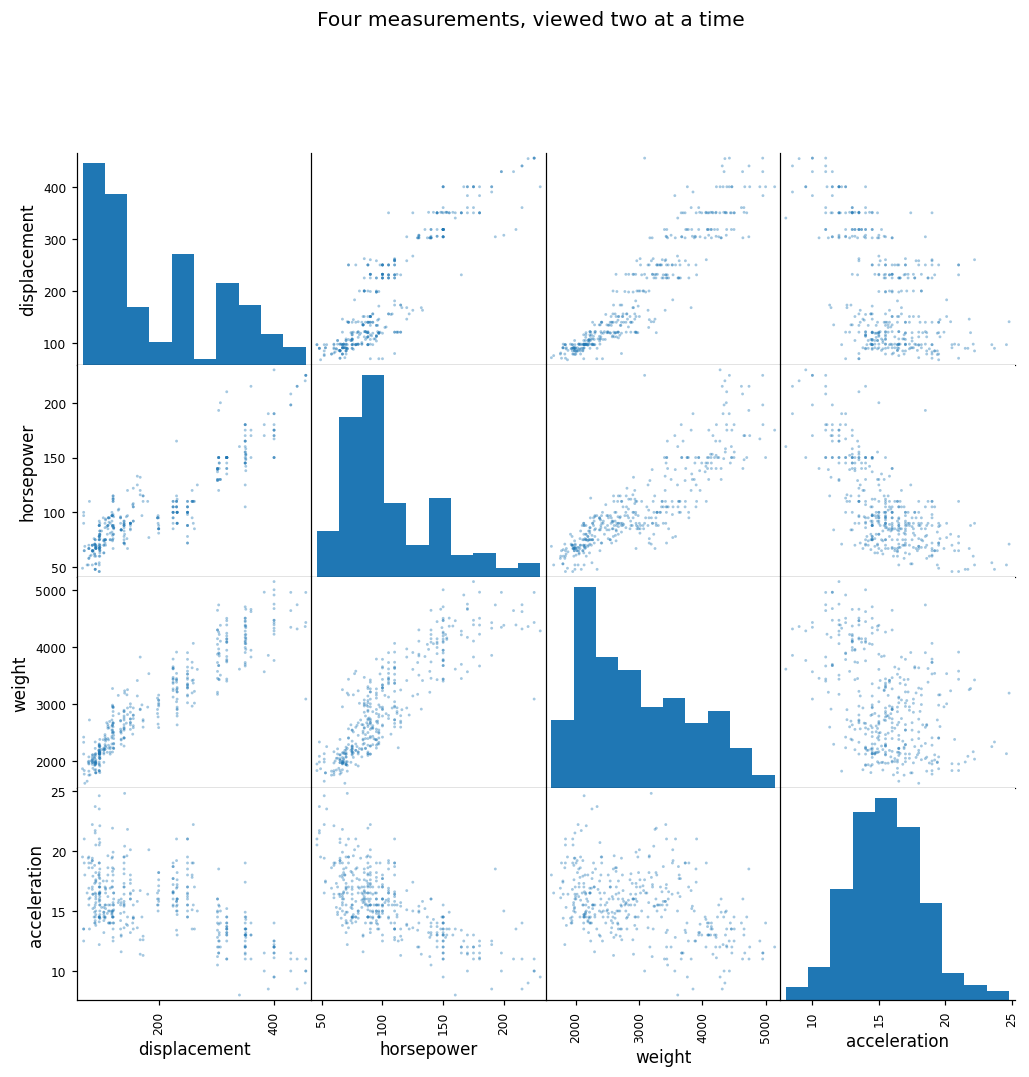

In [5]:
pd.plotting.scatter_matrix(X, figsize=(11,10), diagonal='hist', alpha=.4, s=14)
plt.suptitle('Four measurements, viewed two at a time', y=1.01)
plt.show()


## 3. Why units can change the result
For variable $j$, the mean and variance with divisor $n$ are

$$\mu_j=\frac{1}{n}\sum_i x_{ij},\qquad s_{0j}^2=\frac{1}{n}\sum_i(x_{ij}-\mu_j)^2.$$

Variance measures squared spread around the mean. Weight in pounds has a very different numerical scale from acceleration time in seconds. PCA on raw measurements gives more influence to directions with greater numerical variance.

**Predict** Will expressing the same weights in kilograms change a raw PCA?

In [6]:
X_kg = X.copy()
X_kg['weight'] *= 0.45359237
pca_lb = PCA().fit(X)
pca_kg = PCA().fit(X_kg)
display(pd.DataFrame({'Raw variance': X.var(ddof=0),
                      'PC1 absolute weight, pounds': abs(pca_lb.components_[0]),
                      'PC1 absolute weight, kilograms': abs(pca_kg.components_[0])}).round(4))


,Raw variance,"PC1 absolute weight, pounds","PC1 absolute weight, kilograms"
displacement,10922.4329,0.1143,0.2470
horsepower,1477.7899,0.0390,0.0841
weight,719644.1868,0.9927,0.9653
acceleration,7.5919,0.0014,0.0030


## 4. Calculate the z-score by hand
$$z_{ij}=\frac{x_{ij}-\mu_j}{s_{0j}}.$$

Subtract the column mean, then divide by its standard deviation. A value of $+1$ means one standard deviation above the mean of that measurement. The result has no physical unit.

We use divisor $n$ (`ddof=0`) for this step to match `StandardScaler`. Each standardized column has mean zero and variance one. This gives each measurement equal initial variance, an explicit modeling choice.

,Original,Mean,Difference,Standard deviation,Z-score
displacement,307.0,194.4120,112.5880,104.5104,1.0773
horsepower,130.0,104.4694,25.5306,38.4420,0.6641
weight,3504.0,2977.5842,526.4158,848.3184,0.6205
acceleration,12.0,15.5413,-3.5413,2.7553,-1.2853


,Mean after scaling,Variance after scaling
displacement,-0.0,1.0
horsepower,-0.0,1.0
weight,-0.0,1.0
acceleration,0.0,1.0


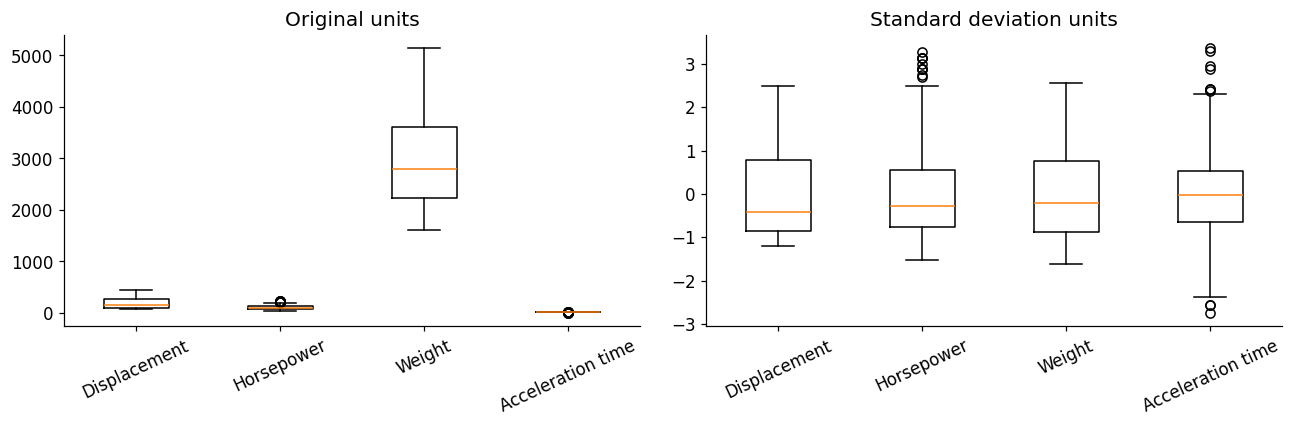

First car: chevrolet chevelle malibu


In [7]:
mu = X.mean()
centered = X - mu
variance = (centered ** 2).mean()
sigma = np.sqrt(variance)
Z = centered / sigma
print('First car:', data.loc[0, 'name'])
display(pd.DataFrame({'Original': X.iloc[0], 'Mean': mu,
                      'Difference': centered.iloc[0], 'Standard deviation': sigma,
                      'Z-score': Z.iloc[0]}).round(4))
display(pd.DataFrame({'Mean after scaling': Z.mean(),
                      'Variance after scaling': Z.var(ddof=0)}).round(8))
assert np.allclose(Z.mean(), 0)
assert np.allclose(Z.var(ddof=0), 1)
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].boxplot(X.to_numpy(), tick_labels=labels)
axes[1].boxplot(Z.to_numpy(), tick_labels=labels)
axes[0].set_title('Original units'); axes[1].set_title('Standard deviation units')
for ax in axes: ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()


## 5. Covariance connects pairs of measurements
$$C=\frac{Z^\top Z}{n-1},\qquad C_{jk}=\frac{1}{n-1}\sum_i z_{ij}z_{ik}.$$

A positive product means two measurements lie on the same side of their respective means. A negative product means they lie on opposite sides. Averaging these products describes how the variables vary together.

Here covariance uses divisor $n-1$, matching the sample variance reported by scikit-learn PCA. Because scaling used $n$, the diagonal of $C$ equals $n/(n-1)$. The correlation matrix is $R=C(n-1)/n$. The common multiplier changes eigenvalues but preserves directions and explained-variance ratios.

,Weight z,Horsepower z,Product
0,0.621,0.664,0.412
1,0.843,1.575,1.328
2,0.540,1.184,0.640
3,0.537,1.184,0.636
4,0.556,0.924,0.514


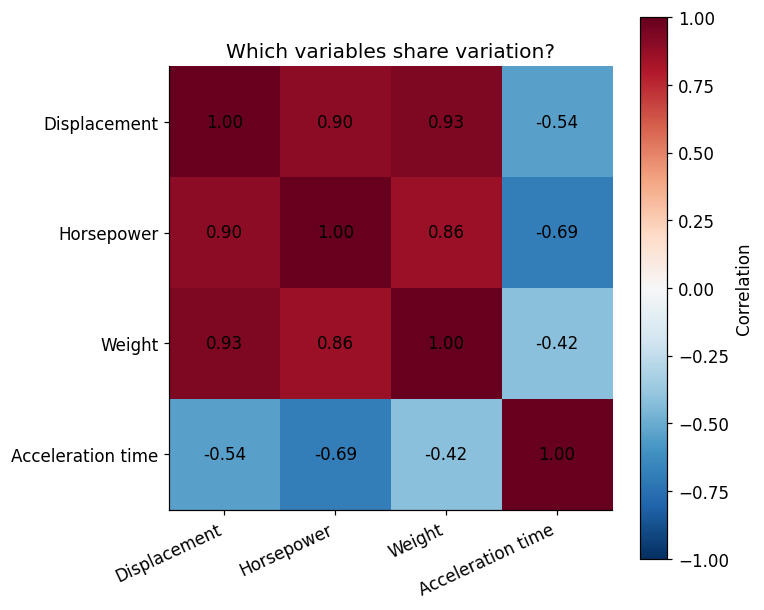

Weight–horsepower sample covariance: 0.8667488315321343


In [8]:
n, p = Z.shape
C = Z.to_numpy().T @ Z.to_numpy() / (n-1)
R = C * (n-1) / n
products = Z['weight'] * Z['horsepower']
display(pd.DataFrame({'Weight z': Z['weight'], 'Horsepower z': Z['horsepower'],
                      'Product': products}).head().round(3))
print('Weight–horsepower sample covariance:', products.sum()/(n-1))
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(R, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(p), labels, rotation=25, ha='right'); ax.set_yticks(range(p), labels)
for i in range(p):
    for j in range(p): ax.text(j,i,f'{R[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im, ax=ax, label='Correlation'); ax.set_title('Which variables share variation?')
plt.tight_layout(); plt.show()


## 6. Find a useful direction by rotating a line
Start with two variables, displacement and weight. A unit direction is $w=(\cos\theta,\sin\theta)$. Projecting a car onto that direction gives one coordinate

$$t_i=z_i^\top w,\qquad \operatorname{Var}(t)=w^\top Cw.$$

We seek the direction with the greatest projected variance. Requiring $\|w\|=1$ prevents increasing variance merely by stretching the direction vector.

Change `angle` to 0, 45 and 90. Gray segments show what is lost when replacing a point by its projection. Which angle preserves the most spread?

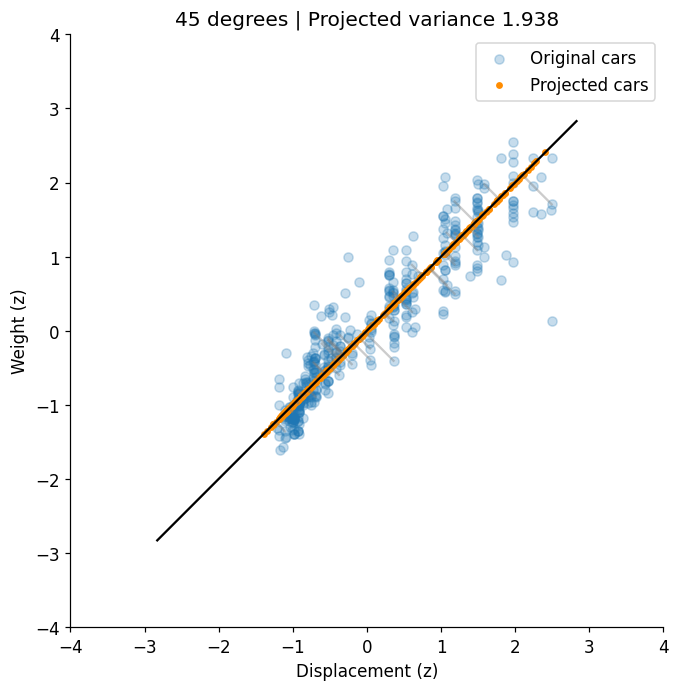

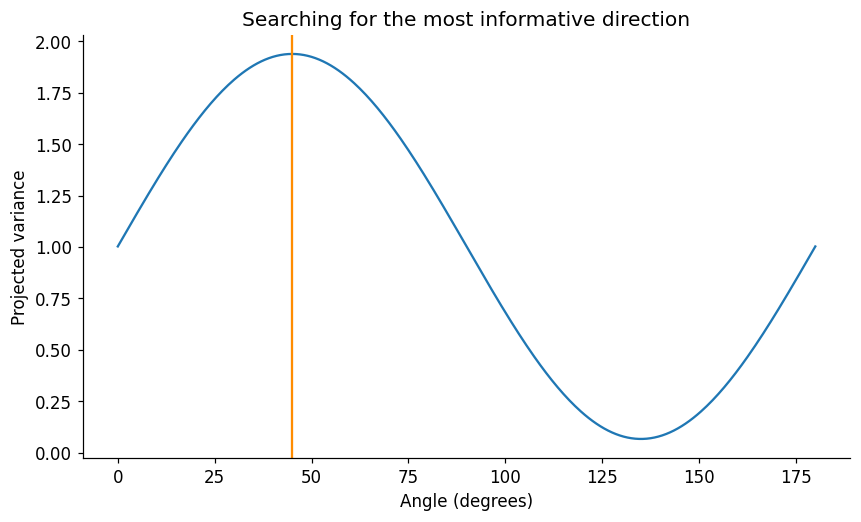

Best angle in this search: 45.0


In [9]:
angle = 45
pair = Z[['displacement', 'weight']].to_numpy()
w = np.array([np.cos(np.deg2rad(angle)), np.sin(np.deg2rad(angle))])
scores_1d = pair @ w
projected = np.outer(scores_1d, w)
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(*pair.T, alpha=.25, label='Original cars')
ax.scatter(*projected.T, s=12, color='darkorange', label='Projected cars')
for point, shadow in zip(pair[::8], projected[::8]):
    ax.plot([point[0],shadow[0]], [point[1],shadow[1]], color='gray', alpha=.4)
ax.plot([-4*w[0],4*w[0]],[-4*w[1],4*w[1]],color='black')
ax.set(xlabel='Displacement (z)', ylabel='Weight (z)', xlim=(-4,4), ylim=(-4,4),
       title=f'{angle} degrees | Projected variance {scores_1d.var(ddof=1):.3f}')
ax.set_aspect('equal'); ax.legend(); plt.show()
angles = np.linspace(0,180,361)
directions = np.vstack([np.cos(np.deg2rad(angles)),np.sin(np.deg2rad(angles))])
variances = (pair @ directions).var(axis=0, ddof=1)
plt.plot(angles,variances); plt.axvline(angle,color='darkorange')
plt.xlabel('Angle (degrees)'); plt.ylabel('Projected variance')
plt.title('Searching for the most informative direction'); plt.show()
print('Best angle in this search:', angles[variances.argmax()])


## 7. Generalize to four dimensions
An eigenvector $w_k$ is a principal direction of the covariance matrix. Its eigenvalue $\lambda_k$ gives the variance along that direction.

$$Cw_k=\lambda_kw_k.$$

Sort eigenvalues from largest to smallest. The first component captures maximum variance; each subsequent component captures maximum remaining variance along an orthogonal direction. Component coordinates are uncorrelated, which does not generally imply independence.

$$T=ZW,\qquad r_k=\frac{\lambda_k}{\sum_j\lambda_j}.$$

$Z$ has shape $n\times4$, the directions $W$ have shape $4\times4$, and $T$ contains each car's new coordinates. NumPy solves the eigenvalue problem. We implement scaling, covariance, sorting, projection and explained variance explicitly.

,Variance,Explained %,Cumulative %
PC1,3.217,80.223,80.223
PC2,0.656,16.352,96.575
PC3,0.083,2.074,98.649
PC4,0.054,1.351,100.000


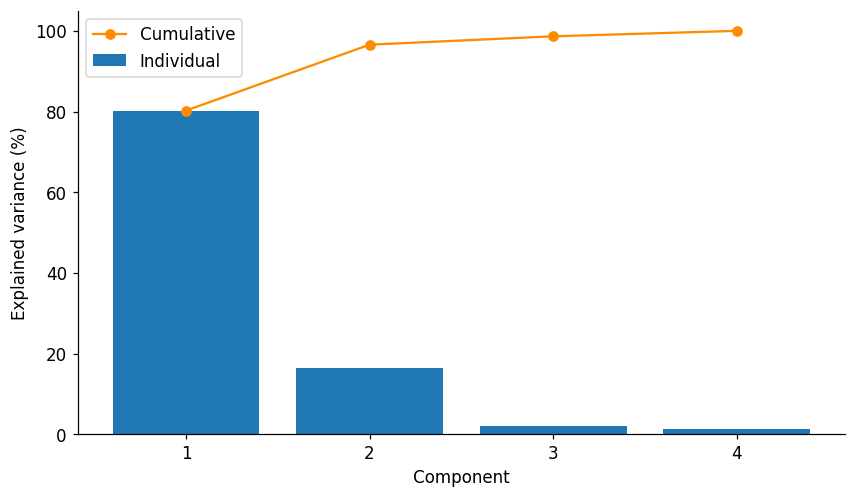

Two coordinates retain 96.57% of standardized variance.


In [10]:
eigenvalues, W = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
W = W[:,order]
# Fix an arbitrary sign convention for reproducible interpretation.
for k in range(p):
    if W[np.abs(W[:,k]).argmax(),k] < 0:
        W[:,k] *= -1
T = Z.to_numpy() @ W
ratios = eigenvalues / eigenvalues.sum()
summary = pd.DataFrame({'Variance': eigenvalues, 'Explained %': ratios*100,
                        'Cumulative %': ratios.cumsum()*100},
                       index=[f'PC{k+1}' for k in range(p)])
display(summary.round(3))
plt.bar(range(1,p+1), ratios*100,label='Individual')
plt.plot(range(1,p+1),ratios.cumsum()*100,'o-',color='darkorange',label='Cumulative')
plt.xticks(range(1,p+1)); plt.xlabel('Component'); plt.ylabel('Explained variance (%)')
plt.legend(); plt.show()
print(f'Two coordinates retain {ratios[:2].sum():.2%} of standardized variance.')


## 8. Interpret the new variables
Each component combines the four z-scores. We call entries of $W$ **weights**. The term *loading* has multiple conventions, so we separately display variable–component correlations.

Read the first equation aloud. Which measurements move together? Which have opposite signs? A direction and its negative describe the same axis, so the overall sign is arbitrary.

The first component can be interpreted through engine size, power, weight and acceleration time together. Give it a descriptive name only after checking the coefficients. A short name is an approximation to the full combination.

,PC1 weight,PC2 weight
Displacement,0.534,0.251
Horsepower,0.542,-0.031
Weight,0.513,0.439
Acceleration time,-0.397,0.862


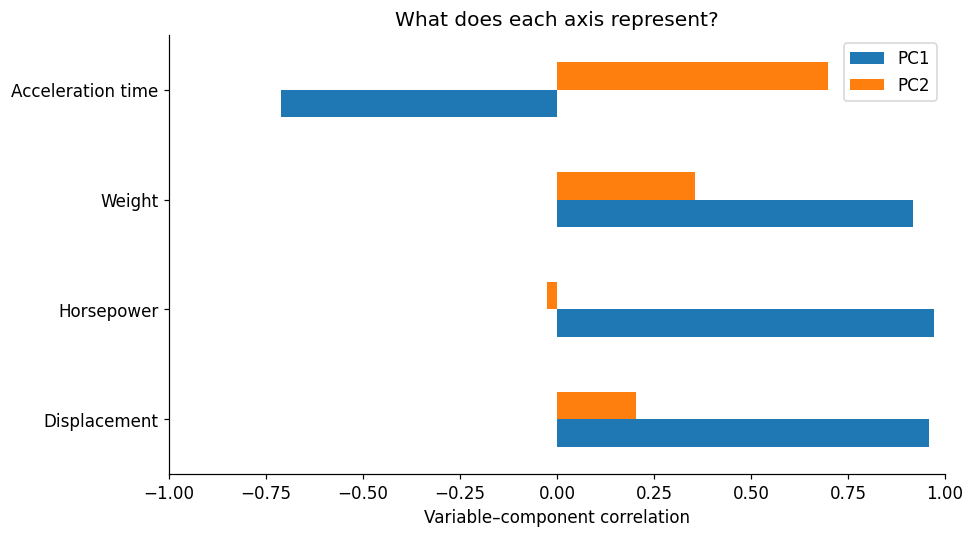

PC1 = +0.534 z(displacement) +0.542 z(horsepower) +0.513 z(weight) -0.397 z(acceleration)
PC2 = +0.251 z(displacement) -0.031 z(horsepower) +0.439 z(weight) +0.862 z(acceleration)


In [11]:
display(pd.DataFrame(W[:,:2],index=labels,columns=['PC1 weight','PC2 weight']).round(3))
for k in range(2):
    print(f'PC{k+1} = ' + ' '.join(f'{W[j,k]:+.3f} z({features[j]})' for j in range(p)))
correlations = np.corrcoef(Z.to_numpy().T,T[:,:2].T)[:p,p:]
pd.DataFrame(correlations,index=labels,columns=['PC1','PC2']).plot.barh(xlim=(-1,1))
plt.xlabel('Variable–component correlation'); plt.title('What does each axis represent?')
plt.tight_layout(); plt.show()


## 9. The reveal — a map built without fuel economy
First inspect the uncolored map. Where are the extremes? Do you see a continuum or distinct groups?

Then run the next cell to reveal MPG. Fuel economy has never entered PCA. A color gradient would show that the unsupervised representation aligns with a useful external measurement. We will inspect what actually appears.

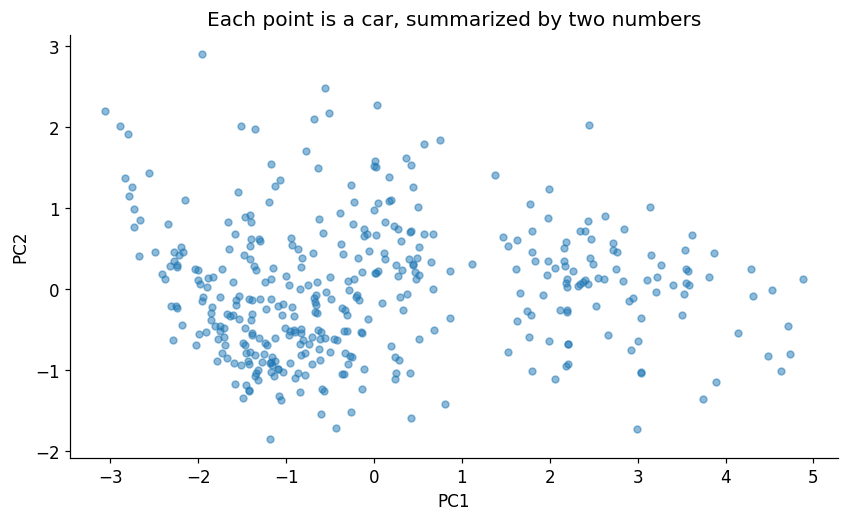

In [12]:
plt.scatter(T[:,0],T[:,1],s=20,alpha=.5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Each point is a car, summarized by two numbers')
plt.show()


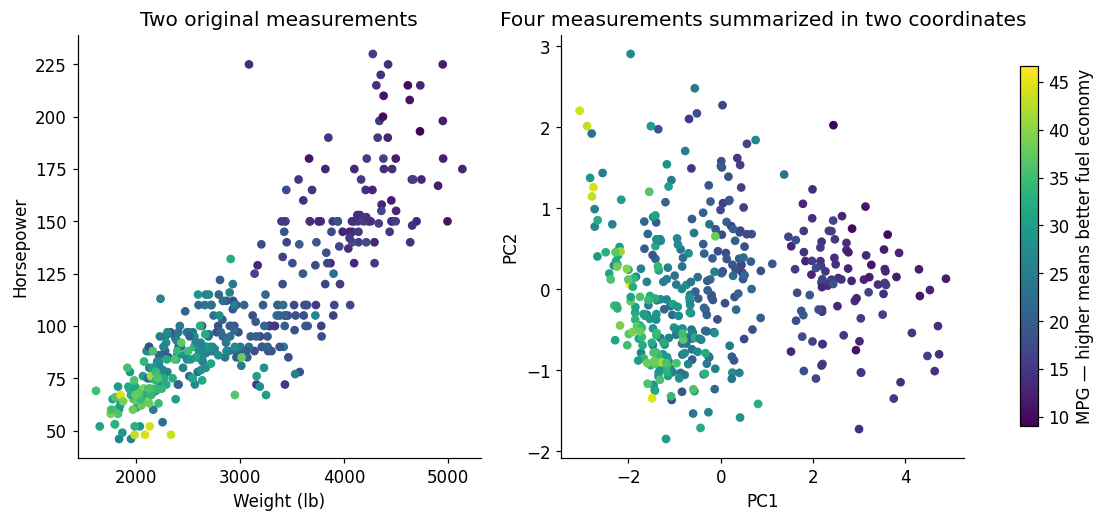

,name,displacement,horsepower,weight,acceleration,mpg,PC1,PC2
94,buick electra 225 custom,455.0,225.0,4951,11.0,12.0,4.88,0.13
201,volkswagen rabbit,97.0,71.0,1825,12.2,29.5,-1.18,-1.85
297,peugeot 504,141.0,71.0,3190,24.8,27.2,-1.95,2.91
388,vw pickup,97.0,52.0,2130,24.6,44.0,-3.06,2.20


In [13]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
vmin, vmax = data['mpg'].min(), data['mpg'].max()
axes[0].scatter(X['weight'],X['horsepower'],c=data['mpg'],cmap='viridis',vmin=vmin,vmax=vmax,s=22)
points = axes[1].scatter(T[:,0],T[:,1],c=data['mpg'],cmap='viridis',vmin=vmin,vmax=vmax,s=22)
axes[0].set(xlabel='Weight (lb)',ylabel='Horsepower',title='Two original measurements')
axes[1].set(xlabel='PC1',ylabel='PC2',title='Four measurements summarized in two coordinates')
fig.colorbar(points,ax=axes,label='MPG — higher means better fuel economy',shrink=.85)
plt.show()
indices = np.unique([T[:,0].argmin(),T[:,0].argmax(),T[:,1].argmin(),T[:,1].argmax()])
examples = data.loc[indices,['name']+features+['mpg']].copy()
examples['PC1'] = T[indices,0]; examples['PC2'] = T[indices,1]
display(examples.round(2))


**Discuss** How does the map relate to fuel economy? What does the table of extreme cars reveal about PC2? The map describes associations in this historical sample. It does not establish that changing a component causes a change in MPG.

## 10. Reconstruct the cars to inspect the information loss
Keeping $q$ components gives an approximation

$$\widehat Z=T_qW_q^\top,\qquad \widehat x_{ij}=\widehat z_{ij}s_{0j}+\mu_j.$$

The average squared reconstruction error in standardized units is

$$MSE_Z=\frac{1}{np}\sum_{i,j}(z_{ij}-\widehat z_{ij})^2.$$

PCA minimizes squared reconstruction error among orthogonal linear projections of the same dimension. The error here is measured in standardized units. More retained components improve reconstruction, while requiring more coordinates.

,Components,Retained variance %,Standardized MSE
0,1,80.2234,0.1978
1,2,96.5750,0.0343
2,3,98.6488,0.0135
3,4,100.0000,0.0000


,Actual,Reconstructed,Error
displacement,307.0,277.61,-29.39
horsepower,130.0,141.91,11.91
weight,3504.0,3526.95,22.95
acceleration,12.0,12.22,0.22


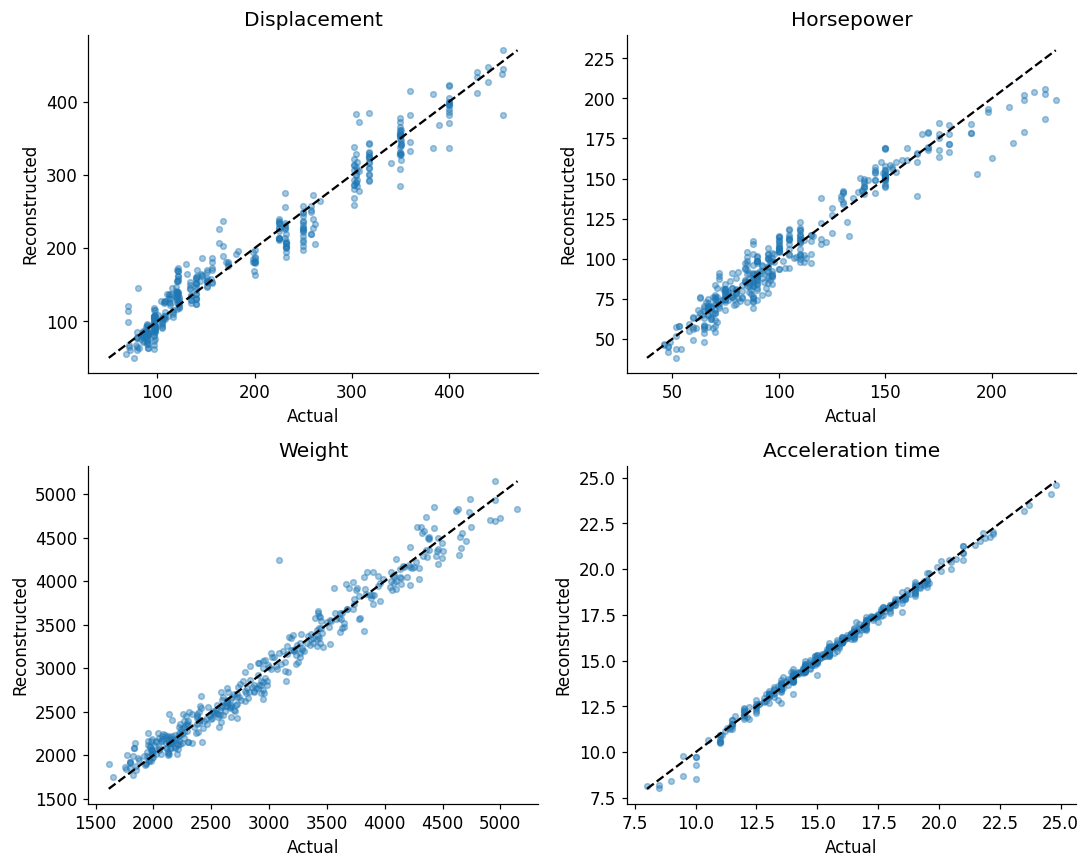

,RMSE in original units,MSE in standardized units
displacement,21.457292,0.042153
horsepower,9.219521,0.057518
weight,147.272350,0.030139
acceleration,0.233654,0.007191


Reconstructing: chevrolet chevelle malibu


In [14]:
rows = []
for q in range(1,p+1):
    approximation = T[:,:q] @ W[:,:q].T
    rows.append([q,100*ratios[:q].sum(),np.mean((Z.to_numpy()-approximation)**2)])
display(pd.DataFrame(rows,columns=['Components','Retained variance %','Standardized MSE']).round(4))
q = 2  # Try 1, 2, 3 and 4.
Z_hat = T[:,:q] @ W[:,:q].T
X_hat = Z_hat * sigma.to_numpy() + mu.to_numpy()
print('Reconstructing:', data.loc[0,'name'])
display(pd.DataFrame({'Actual':X.iloc[0],'Reconstructed':X_hat[0],
                      'Error':X_hat[0]-X.iloc[0]}).round(2))
fig, axes = plt.subplots(2,2,figsize=(10,8))
for j, ax in enumerate(axes.flat):
    ax.scatter(X.iloc[:,j],X_hat[:,j],s=14,alpha=.4)
    limits = [min(X.iloc[:,j].min(),X_hat[:,j].min()),max(X.iloc[:,j].max(),X_hat[:,j].max())]
    ax.plot(limits,limits,'k--')
    ax.set(title=labels[j],xlabel='Actual',ylabel='Reconstructed')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'RMSE in original units':np.sqrt(np.mean((X.to_numpy()-X_hat)**2,axis=0)),
                      'MSE in standardized units':np.mean((Z.to_numpy()-Z_hat)**2,axis=0)},index=features))
assert np.isclose(rows[-1][2],0,atol=1e-12)
assert np.isclose(rows[1][2],1-ratios[:2].sum())


Compare reconstruction errors across variables using standardized units. A numerical error in pounds cannot be directly ranked against one in seconds.

Two coordinates halve the number of columns stored per car. Reconstructing also requires the means, standard deviations and retained directions. Keeping all four components preserves the original measurements up to numerical precision; discarding components creates the approximation.

## 11. Verify the manual calculations with scikit-learn
`StandardScaler` uses the same z-score convention. `PCA` centers its inputs but does not standardize the original variables automatically. We use full SVD for the library calculation, then align the arbitrary signs before comparing scores.

In [15]:
scaler = StandardScaler()
Z_library = scaler.fit_transform(X)
pca = PCA(n_components=p,svd_solver='full')
T_library = pca.fit_transform(Z_library)
signs = np.sign(np.sum(pca.components_.T * W,axis=0))
checks = {
    'Z-scores':np.allclose(Z,Z_library),
    'Eigenvalues':np.allclose(eigenvalues,pca.explained_variance_),
    'Explained variance ratios':np.allclose(ratios,pca.explained_variance_ratio_),
    'Coordinates after sign alignment':np.allclose(T,T_library*signs),
    'Orthonormal directions':np.allclose(W.T@W,np.eye(p)),
    'Eigenvalue equation':np.allclose(C@W,W*eigenvalues)
}
pca_reduced = PCA(n_components=q,svd_solver='full')
compressed = pca_reduced.fit_transform(Z_library)
restored = scaler.inverse_transform(pca_reduced.inverse_transform(compressed))
checks['Reconstruction'] = np.allclose(restored,X_hat)
display(pd.Series(checks,name='Passed'))
assert all(checks.values())
assert np.allclose(StandardScaler().fit_transform(X_kg),Z_library)
print('All manual calculations match scikit-learn. Unit conversion disappears after scaling.')


Z-scores                            True
Eigenvalues                         True
Explained variance ratios           True
Coordinates after sign alignment    True
Orthonormal directions              True
Eigenvalue equation                 True
Reconstruction                      True
Name: Passed, dtype: bool

All manual calculations match scikit-learn. Unit conversion disappears after scaling.


## 12. Apply the same transformation to another car
Once fitted, the representation is defined by the training means, standard deviations and directions. Use those same quantities when a new observation arrives. Recomputing them on each incoming car would change the coordinate system.

Below we demonstrate the API on an existing record; this illustrates transformation, without claiming evaluation on an unseen car.

In [16]:
car = X.iloc[[0]]
manual_coordinates = ((car.to_numpy()-mu.to_numpy())/sigma.to_numpy()) @ W[:,:2]
library_coordinates = pca.transform(scaler.transform(car))[:,:2] * signs[:2]
assert np.allclose(manual_coordinates,library_coordinates)
print(data.loc[0,'name'], manual_coordinates)


chevrolet chevelle malibu [[ 1.7645 -0.5857]]


## 13. Class challenge — explain your choices
1. Find the smallest number of components retaining at least 90% of standardized variance.
2. Explain PC1 to a nontechnical colleague using its actual coefficients.
3. Choose one car with an extreme PC2 value. Explain its position using its measurements.
4. Change `q` in the reconstruction cell. Which measurement suffers most when only one component is retained?
5. Explain why 95% explained variance does not imply 95% accuracy or a 5% error in MPG.
6. Describe a situation where retaining the original variables would be more useful.

Write your answers before opening the numerical check below.

In [17]:
# Your analysis here


<details><summary>Instructor notes and interpretation prompts</summary>

Find the first cumulative variance ratio reaching 0.90. Read PC1 as a weighted combination of standardized measurements, including acceleration time's sign. For an extreme PC2 car, compare all four z-scores before assigning a label. Calculate reconstruction errors in standardized units for fair comparison. Explained variance measures retained input dispersion; predicting MPG requires a supervised evaluation. Original columns remain helpful when an audience needs statements in physical units or a decision tied to a specific measurement.

</details>

In [18]:
q_90 = np.searchsorted(ratios.cumsum(),.90)+1
print('Minimum components for 90% variance:',q_90)
one_component = T[:,:1] @ W[:,:1].T
display(pd.Series(np.mean((Z.to_numpy()-one_component)**2,axis=0),index=features,
                  name='Standardized MSE with one component').sort_values(ascending=False))


acceleration    0.493297
weight          0.156272
displacement    0.083352
horsepower      0.058143
Name: Standardized MSE with one component, dtype: float64

Minimum components for 90% variance: 2


## 14. Optional extension — does compression help MPG prediction?
The map demonstrated visualization and compression. Test prediction separately using linear regression with four original variables or two components.

Each pipeline fits scaling and PCA inside the training fold to avoid leakage. Both use identical five-fold splits. The metric is mean absolute error in MPG, where lower is better. The standard deviation describes variation across folds, rather than a confidence interval.

Random splits estimate performance within this historical sample. Prediction for future model years would require a time-aware evaluation. There is no guarantee that high-variance directions are the most predictive ones.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
cv = KFold(n_splits=5,shuffle=True,random_state=42)
models = {
    'Four original variables':make_pipeline(StandardScaler(),LinearRegression()),
    'Two principal components':make_pipeline(StandardScaler(),PCA(n_components=2),LinearRegression())
}
results=[]
for name,model in models.items():
    errors = -cross_val_score(model,X,data['mpg'],cv=cv,scoring='neg_mean_absolute_error')
    results.append([name,errors.mean(),errors.std()])
display(pd.DataFrame(results,columns=['Representation','Mean MAE (MPG)','SD across folds']))


,Representation,Mean MAE (MPG),SD across folds
0,Four original variables,3.296705,0.249291
1,Two principal components,3.309760,0.273054


## Visual resources and references
- [PCA Explained Visually — Victor Powell and Lewis Lehe](https://setosa.io/ev/principal-component-analysis/) provides an interactive projection explanation suitable for the rotating-axis demonstration.
- [UCI Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) documents the dataset. The embedded CSV is the [seaborn distribution](https://github.com/mwaskom/seaborn-data/blob/master/mpg.csv), retrieved on 13 November 2026.
- [StandardScaler documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) explains the scaling convention.
- [PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) explains components, variance and inverse transformation.

All charts in this notebook are generated from the embedded data. To export a figure for slides, add `fig.savefig("pca_chart.png", dpi=200, bbox_inches="tight")` before its `plt.show()` call. Check attribution conditions when reusing external illustrations.

**Closing question** What did you gain by representing a car with two coordinates, and which questions still require its original measurements?